# 04 · Resultados y evaluación

Fase CRISP-DM: **Evaluación**.

Compara todos los modelos con las mismas fotos. Primero se genera la evaluación:
```
python -m src.main evaluar          # val: se puede repetir
```
Y solo al final, una vez:
```
python -m src.main congelar
python -m src.main evaluar --test --confirmo
```

**Cómo leer las métricas**
- **F1 macro**: promedio del F1 de good, regular y bad. Así la clase con menos fotos (regular) pesa lo mismo que las demás.
- **Malas como buenas**: frutas malas que el modelo dejaría pasar como buenas. Es el error más caro para el negocio.
- **IC 95 %**: rango probable del F1 si se repitiera con otras fotos. Se calcula remuestreando **grupos** completos, porque las fotos de un grupo se parecen entre sí.

In [1]:
from pathlib import Path
import json
import sys

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "src" / "config.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import pandas as pd

from src import config

def read(name):
    """Lee un resultado de results/; si no existe, explica qué comando lo genera."""
    path = config.RESULTS / name
    if not path.is_file():
        raise FileNotFoundError(f"Falta {path}. Corre primero los pasos del README.")
    return json.loads(path.read_text(encoding="utf-8"))

config.FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
partition = "test" if (config.RESULTS / "evaluacion_test.json").is_file() else "val"
report = read(f"evaluacion_{partition}.json")
print(f"Partición: {partition} · {report['n']} recortes en {report['n_groups']} grupos")
pd.DataFrame([{"modelo": name, "F1 macro": round(m["f1_macro"], 3),
               "F1 Kaggle (2 clases)": round(m.get("f1_kaggle", float("nan")), 3),
               "F1 AgriFreshNET (3 clases)": round(m.get("f1_agrifreshnet", float("nan")), 3),
               "F1 AFruitDB (3 clases)": round(m.get("f1_afruitdb", float("nan")), 3),
               "recall bad": round(m["recall_bad"], 3), "malas como buenas": m["bad_to_good"]}
              for name, m in report["models"].items()])

Partición: val · 3605 recortes en 129 grupos


,modelo,F1 macro,F1 Kaggle (2 clases),F1 AgriFreshNET (3 clases),F1 AFruitDB (3 clases),recall bad,malas como buenas
0,logistic_regression,0.706,0.872,0.613,0.683,0.824,124
1,svm_linear,0.699,0.886,0.604,0.681,0.858,122
2,random_forest,0.762,0.966,0.661,0.655,0.948,41
3,cnn,0.738,0.950,0.661,0.641,0.878,120
4,ensemble,0.769,0.964,0.699,0.695,0.919,82


In [3]:
final = report.get("final_model", "random_forest")
lo, hi = report["models"][final]["f1_macro_ci95"]
print(f"Modelo final ({final}): F1 {report['models'][final]['f1_macro']:.3f}, IC 95 % [{lo:.3f}; {hi:.3f}]")
print(f"Fruta: accuracy {report['fruit']['accuracy']:.3f}, F1 macro {report['fruit']['f1_macro']:.3f}")

Modelo final (random_forest): F1 0.762, IC 95 % [0.697; 0.850]
Fruta: accuracy 0.869, F1 macro 0.800


## ¿El modelo aprendió `regular` o el estilo de una fuente?

Casi todos los `regular` vienen de AgriFreshNET. Si el modelo acierta `regular` en AgriFreshNET pero no en AFruitDB (otra fuente, con fotos de celular), aprendió el estilo de AgriFreshNET y no el estado de la fruta. Cada celda es el porcentaje de frutas `regular` reales que el modelo llamó `regular`.

In [4]:
pd.DataFrame({name: m.get("recall_regular_by_source", {}) for name, m in report["models"].items()}).T.mul(100).round(1)

,afruitdb,agrifreshnet,own
logistic_regression,68.6,56.9,100.0
svm_linear,60.2,47.2,100.0
random_forest,79.9,58.1,0.0
cnn,38.3,45.9,0.0
ensemble,45.8,51.2,0.0


## Matrices de confusión

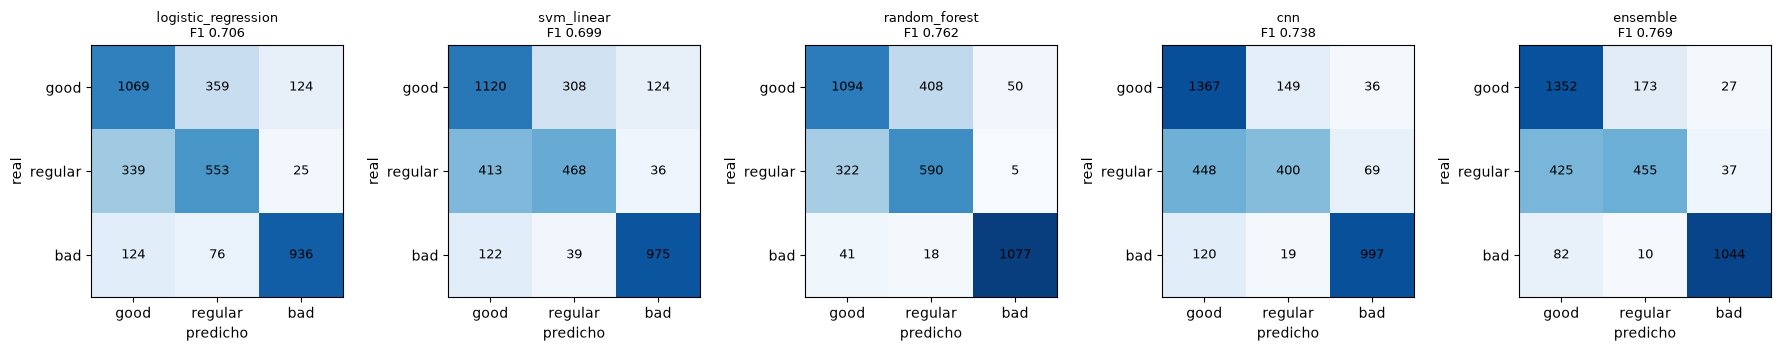

In [5]:
import numpy as np

names = list(report["models"])
fig, axes = plt.subplots(1, len(names), figsize=(3.6 * len(names), 3.4))
for ax, name in zip(axes, names):
    m = report["models"][name]
    matrix = np.asarray(m["confusion_matrix"])
    ax.imshow(matrix / matrix.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(3), m["labels"]); ax.set_yticks(range(3), m["labels"])
    for i in range(3):
        for j in range(3):
            ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=9)
    ax.set_title(f"{name}\nF1 {m['f1_macro']:.3f}", fontsize=9)
    ax.set_xlabel("predicho"); ax.set_ylabel("real")
fig.tight_layout()
fig.savefig(config.FIGURES / f"confusion_{partition}.png", dpi=150)

## Fruta: qué se confunde con qué

In [6]:
fruit = report["fruit"]
pd.DataFrame(fruit["confusion_matrix"], index=fruit["labels"], columns=fruit["labels"])

,apple,banana,bitter_melon,cucumber,eggplant,guava,lime,mango,orange,papaya,pineapple,pomegranate,tomato
apple,205,8,0,0,1,0,3,0,9,0,0,62,1
banana,0,680,0,0,0,3,0,1,2,0,0,0,0
bitter_melon,0,1,18,0,0,0,0,0,0,0,0,0,0
cucumber,0,3,0,131,0,0,0,0,0,0,0,0,0
eggplant,4,1,0,0,88,0,0,0,0,1,2,0,0
guava,21,6,0,0,7,105,0,0,8,0,0,0,0
lime,28,42,0,0,0,4,204,0,1,0,0,0,2
mango,0,0,0,0,0,0,0,10,2,0,0,0,0
orange,2,17,1,11,2,1,9,0,700,19,0,0,0
papaya,2,18,28,0,8,1,0,7,12,252,3,0,0


## Prueba de fuga (opcional): `python -m src.main fuga`

Misma validación cruzada, cambiando solo cómo se agrupan las fotos de AgriFreshNET. Si el F1 baja al agrupar más grueso, con grupos finos la nota estaba inflada. La última columna debe dar 0 en "week": ninguna foto de val comparte semana con train.

In [7]:
if (config.RESULTS / "prueba_fuga.json").is_file():
    leak = read("prueba_fuga.json")
    display(pd.DataFrame([{"agrupación": level, "grupos en train": item["train_groups"],
                           "F1 AgriFreshNET": round(item["cv"]["agrifreshnet_3cl"]["mean"], 3),
                           "F1 global": round(item["cv"]["overall"]["mean"], 3),
                           "val que comparte sesión con train":
                               item["crossing"]["val_agri_rows_sharing_session_with_train"]}
                          for level, item in leak["levels"].items()]))
else:
    print("Aún no se corrió la prueba de fuga.")

Aún no se corrió la prueba de fuga.


## Fotos de celular, mitad "prueba": `python -m src.main celular evaluar --confirmo`

La prueba más cercana al uso real: fotos tomadas por la clase con celulares, de sesiones que el modelo nunca vio (la otra mitad de las sesiones sí entrenó), con el estado etiquetado sin mirar la app.

In [8]:
if (config.RESULTS / "evaluacion_celular.json").is_file():
    phone = read("evaluacion_celular.json")
    print(f"{phone['n']} fotos de {phone['sessions']} sesiones · "
          f"fruta: accuracy {phone['fruit']['accuracy']:.3f} {phone['fruit']['accuracy_ci95']}")
    display(pd.DataFrame([{"modelo": n, "F1 macro": round(q["f1_macro"], 3),
                           "IC 95 %": [round(v, 3) for v in q["f1_macro_ci95"]],
                           "malas como buenas": q["bad_to_good"]}
                          for n, q in phone["quality"].items()]))
else:
    print("Aún no se evaluaron las fotos de celular.")

Aún no se evaluaron las fotos de celular.
